# NMF baseline diagnostics

This notebook compares two small NMF models on only the first 30 seconds of `outputs/synthetic_mixture.wav`. The mixture was made from separate sitar and tabla performances; they are not aligned stems from one original recording, so this experiment cannot provide ground-truth separation scores.

NMF components are anonymous patterns, not automatically instruments. A smaller magnitude reconstruction error means a closer fit to the mixture spectrogram, not necessarily better sitar/tabla separation. Component estimates reuse the mixture's phase, which can introduce audible artifacts. No component audio is saved.

## Load only the analysis segment

We inspect the WAV header first, then ask `soundfile` to read no more than 30 seconds. This avoids loading the full file when it is longer. Stereo channels, if present, are averaged to mono.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from scipy import signal
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning

root_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (
        candidate
        for candidate in root_candidates
        if (candidate / "outputs" / "synthetic_mixture.wav").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find outputs/synthetic_mixture.wav.")

mixture_path = PROJECT_ROOT / "outputs" / "synthetic_mixture.wav"
if not mixture_path.is_file():
    raise FileNotFoundError(f"Mixture file not found: {mixture_path}")

file_info = sf.info(mixture_path)
sample_rate = file_info.samplerate
maximum_samples = 30 * sample_rate
mixture_audio, sample_rate = sf.read(
    mixture_path,
    dtype="float32",
    frames=maximum_samples,
    always_2d=True,
)

if mixture_audio.shape[0] == 0:
    raise ValueError("The mixture file contains no audio samples.")
if not np.isfinite(mixture_audio).all():
    raise ValueError("The mixture contains NaN or infinite values.")

mixture_mono = mixture_audio.mean(axis=1)
if not np.isfinite(mixture_mono).all():
    raise ValueError("Mono conversion produced NaN or infinite values.")

duration_seconds = len(mixture_mono) / sample_rate
print(f"Input: {mixture_path}")
print(f"Analyzed duration: {duration_seconds:.2f} seconds")
print(f"Sample rate: {sample_rate} Hz; samples: {len(mixture_mono)}")

Input: d:\indian-instrument-separation\outputs\synthetic_mixture.wav
Analyzed duration: 30.00 seconds
Sample rate: 44100 Hz; samples: 1323000


## Create the input magnitude spectrogram

We keep the baseline notebook's SciPy STFT settings: Hann window, 2048-sample segments, 1024-sample overlap, one-sided spectrum, zero boundary extension, and a spectrum-scaled STFT. The magnitude is non-negative, as required by NMF. These settings produce about 1025 frequency bins and roughly 1293 frames for a 30-second, 44.1 kHz input.

In [3]:
nperseg = 2048
noverlap = 1024
hop_length = nperseg - noverlap
component_counts = (2, 4)
random_seed = 0
maximum_iterations = 100
tolerance = 1e-3

frequencies, times, mixture_stft = signal.stft(
    mixture_mono,
    fs=sample_rate,
    window="hann",
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=nperseg,
    return_onesided=True,
    boundary="zeros",
    padded=True,
    scaling="spectrum",
)
magnitude = np.abs(mixture_stft).astype(np.float32)

if magnitude.ndim != 2 or not np.isfinite(magnitude).all():
    raise ValueError("The input magnitude spectrogram must be a finite 2D array.")
if np.any(magnitude < 0):
    raise ValueError("The NMF input must be non-negative.")
if magnitude.shape[0] != len(frequencies) or magnitude.shape[1] != len(times):
    raise ValueError("STFT frequency/time axes do not match the spectrogram dimensions.")

print(f"Magnitude spectrogram shape (frequency bins, frames): {magnitude.shape}")
print(f"STFT settings: nperseg={nperseg}, noverlap={noverlap}, hop={hop_length}")
print(f"NMF settings: init=nndsvda, solver=cd, max_iter={maximum_iterations}, tol={tolerance}, seed={random_seed}")

Magnitude spectrogram shape (frequency bins, frames): (1025, 1293)
STFT settings: nperseg=2048, noverlap=1024, hop=1024
NMF settings: init=nndsvda, solver=cd, max_iter=100, tol=0.001, seed=0


## Plot the mixture spectrogram

The plot shows where energy appears over time and frequency. It does not identify which instrument created any region.

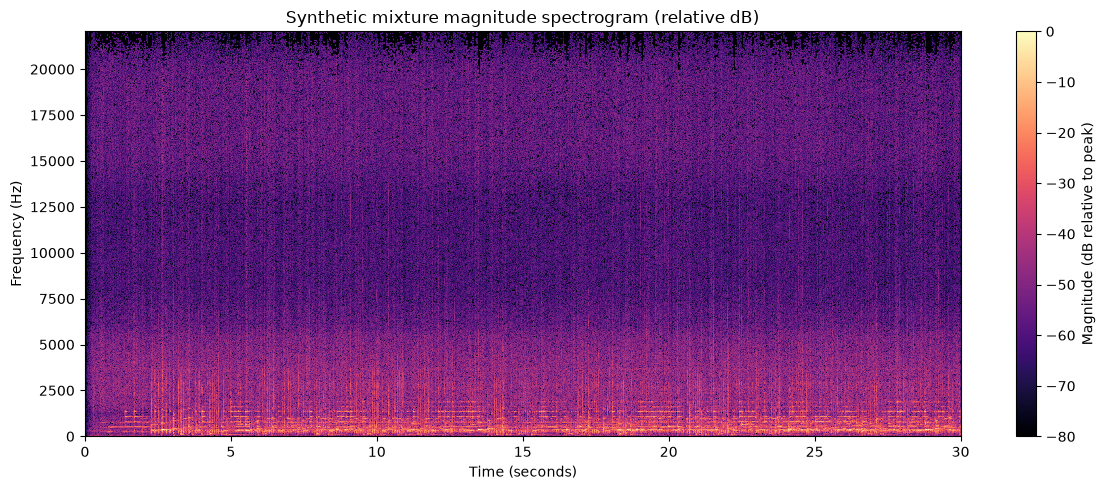

In [4]:
magnitude_db = 20 * np.log10(np.maximum(magnitude, 1e-8) / max(float(magnitude.max()), 1e-8))
plt.figure(figsize=(12, 5))
image = plt.pcolormesh(times, frequencies, magnitude_db, shading="auto", cmap="magma", vmin=-80, vmax=0)
plt.title("Synthetic mixture magnitude spectrogram (relative dB)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(image, label="Magnitude (dB relative to peak)")
plt.tight_layout()
plt.show()

## Fit comparable 2- and 4-component models

Scikit-learn expects rows to be observations and columns to be features. We therefore give it frames-by-frequency data. Its `components_` matrix is W (components by frequency), and `fit_transform` returns H transposed (frames by components). Both models use the same input, initialization, solver, iteration limit, tolerance, and random seed. The metric is the Frobenius norm of `V - W.T @ H.T`, plus the same error divided by the input norm.

In [5]:
models = {}
metrics = {}
component_magnitudes_by_count = {}
component_audio_by_count = {}

input_norm = np.linalg.norm(magnitude)
if not np.isfinite(input_norm) or input_norm == 0:
    raise ValueError("The input spectrogram norm must be finite and non-zero.")

for component_count in component_counts:
    model = NMF(
        n_components=component_count,
        init="nndsvda",
        solver="cd",
        beta_loss="frobenius",
        max_iter=maximum_iterations,
        tol=tolerance,
        random_state=random_seed,
    )

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        activations = model.fit_transform(magnitude.T)

    patterns = model.components_
    if patterns.shape != (component_count, magnitude.shape[0]):
        raise ValueError(f"Unexpected W shape for {component_count} components: {patterns.shape}.")
    if activations.shape != (magnitude.shape[1], component_count):
        raise ValueError(f"Unexpected H shape for {component_count} components: {activations.shape}.")
    if not np.isfinite(patterns).all() or not np.isfinite(activations).all():
        raise ValueError(f"NMF produced non-finite values for {component_count} components.")
    if np.any(patterns < 0) or np.any(activations < 0):
        raise ValueError(f"NMF produced negative factors for {component_count} components.")

    reconstructed = patterns.T @ activations.T
    if reconstructed.shape != magnitude.shape:
        raise ValueError(f"Unexpected reconstructed spectrogram shape: {reconstructed.shape}.")
    if not np.isfinite(reconstructed).all():
        raise ValueError("NMF reconstruction contains NaN or infinite values.")

    absolute_error = float(np.linalg.norm(magnitude - reconstructed))
    relative_error = absolute_error / input_norm
    metrics[component_count] = {
        "absolute_frobenius_error": absolute_error,
        "relative_frobenius_error": relative_error,
        "iterations": model.n_iter_,
        "converged_without_warning": not any(
            issubclass(item.category, ConvergenceWarning) for item in caught_warnings
        ),
    }
    models[component_count] = (model, activations)

    individual_magnitudes = np.stack(
        [patterns[index, :, None] * activations[:, index][None, :] for index in range(component_count)]
    )
    reconstructed_from_parts = individual_magnitudes.sum(axis=0)
    if individual_magnitudes.shape != (component_count, *magnitude.shape):
        raise ValueError(f"Unexpected component magnitude dimensions: {individual_magnitudes.shape}.")
    if not np.isfinite(individual_magnitudes).all():
        raise ValueError("NMF component magnitudes contain non-finite values.")
    if not np.allclose(reconstructed_from_parts, reconstructed, rtol=1e-4, atol=1e-7):
        raise ValueError("Summed component magnitudes do not match the NMF reconstruction.")

    component_magnitudes_by_count[component_count] = individual_magnitudes

print("NMF magnitude-reconstruction results:")
for component_count, result in metrics.items():
    status = "yes" if result["converged_without_warning"] else "warning reported"
    print(
        f"  {component_count} components: absolute error={result['absolute_frobenius_error']:.6f}, "
        f"relative error={result['relative_frobenius_error']:.6f}, "
        f"iterations={result['iterations']}, no convergence warning={status}"
    )

NMF magnitude-reconstruction results:
  2 components: absolute error=0.916499, relative error=0.524585, iterations=35, no convergence warning=yes
  4 components: absolute error=0.733458, relative error=0.419816, iterations=45, no convergence warning=yes


## Visualize W frequency patterns and H time activations

Each row of W is one learned frequency pattern; each column of H describes its activation over frames. For display only, each W row is scaled to a peak of one and H is scaled inversely, preserving their product. The component numbers are arbitrary labels, not sitar/tabla assignments. Broad or overlapping patterns are not proof of instrument identity.

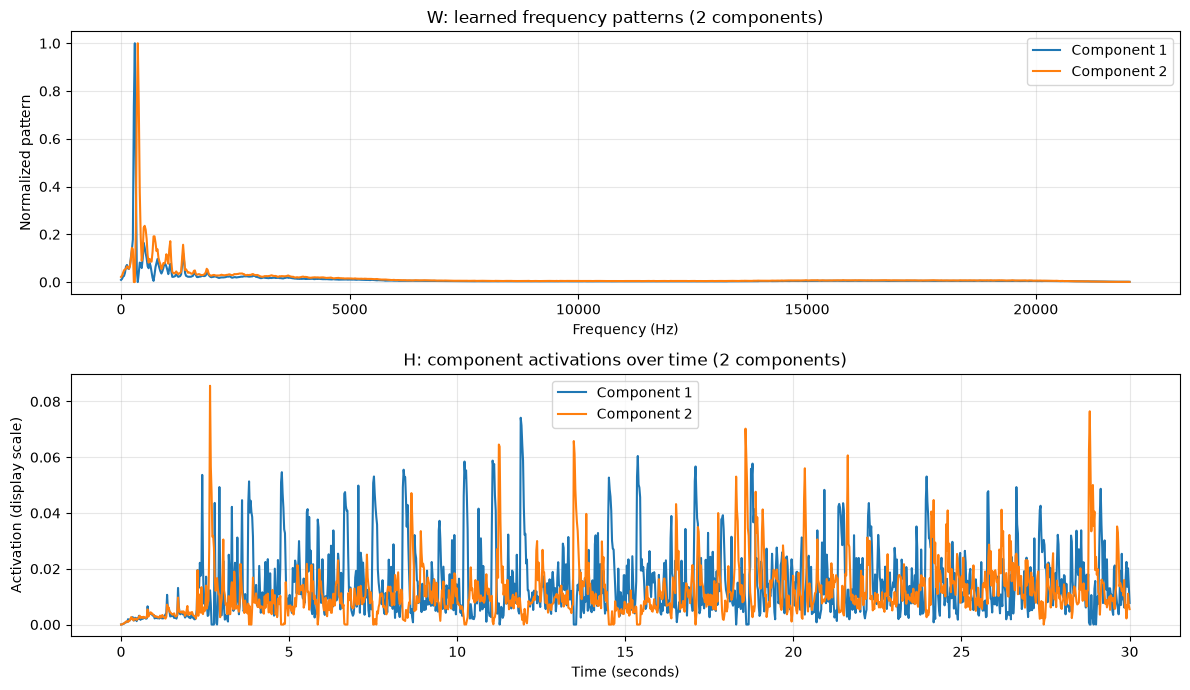

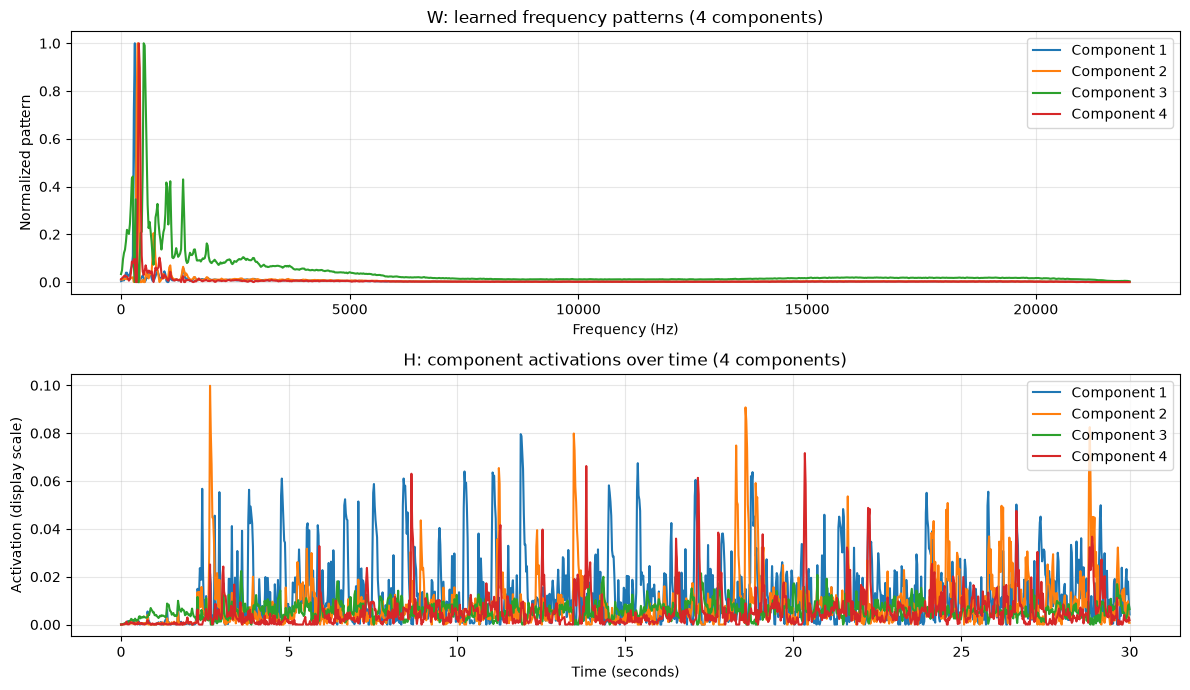

In [6]:
for component_count in component_counts:
    model, activations = models[component_count]
    patterns = model.components_
    pattern_peaks = np.maximum(patterns.max(axis=1), np.finfo(np.float32).eps)
    display_patterns = patterns / pattern_peaks[:, None]
    display_activations = activations * pattern_peaks[None, :]

    fig, axes = plt.subplots(2, 1, figsize=(12, 7))
    for index in range(component_count):
        axes[0].plot(frequencies, display_patterns[index], label=f"Component {index + 1}")
    axes[0].set_title(f"W: learned frequency patterns ({component_count} components)")
    axes[0].set_xlabel("Frequency (Hz)")
    axes[0].set_ylabel("Normalized pattern")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    for index in range(component_count):
        axes[1].plot(times, display_activations[:, index], label=f"Component {index + 1}")
    axes[1].set_title(f"H: component activations over time ({component_count} components)")
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("Activation (display scale)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()

## Check anonymous phase-based component estimates

For each model, the component magnitude contributions are converted to soft masks and applied to the mixture's complex STFT. Each masked STFT is inverted with the matching SciPy settings. This is illustrative only: all components reuse the mixture phase, which can create artifacts, and neither components nor their sum are ground-truth instrument stems.

In [7]:
for component_count in component_counts:
    individual_magnitudes = component_magnitudes_by_count[component_count]
    total_magnitude = individual_magnitudes.sum(axis=0)
    denominator = np.maximum(total_magnitude, np.finfo(np.float32).eps)
    masks = individual_magnitudes / denominator[None, :, :]
    masked_stfts = masks * mixture_stft[None, :, :]

    estimates = []
    for index in range(component_count):
        _, estimate = signal.istft(
            masked_stfts[index],
            fs=sample_rate,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nperseg,
            input_onesided=True,
            boundary=True,
            scaling="spectrum",
        )

        extra_samples = len(estimate) - len(mixture_mono)
        if extra_samples < 0 or extra_samples >= hop_length:
            raise ValueError(
                f"Component {index + 1} in the {component_count}-component model has "
                f"unexpected length {len(estimate)}."
            )
        estimate = estimate[: len(mixture_mono)]
        if estimate.shape != mixture_mono.shape or not np.isfinite(estimate).all():
            raise ValueError(f"Invalid estimate for component {index + 1} in the {component_count}-component model.")
        estimates.append(estimate)

    estimates = np.stack(estimates)
    if estimates.shape != (component_count, len(mixture_mono)):
        raise ValueError(f"Unexpected component audio dimensions: {estimates.shape}.")
    if not np.isfinite(estimates).all():
        raise ValueError("Component audio contains NaN or infinite values.")

    summed_estimate = estimates.sum(axis=0)
    summed_peak = float(np.max(np.abs(summed_estimate)))
    if not np.isfinite(summed_peak):
        raise ValueError("Summed component audio has a non-finite peak.")

    component_audio_by_count[component_count] = estimates
    print(
        f"{component_count}-component model: estimate shape={estimates.shape}, "
        f"all finite=yes, summed peak={summed_peak:.6f}"
    )

2-component model: estimate shape=(2, 1323000), all finite=yes, summed peak=0.497040
4-component model: estimate shape=(4, 1323000), all finite=yes, summed peak=0.497040


## Interpretation and limitations

Compare the printed relative Frobenius errors to see which model fits this mixture magnitude more closely. With more components, the fit often becomes more flexible, so a smaller error is not evidence of better instrument separation. The W/H plots show patterns and their timing, but NMF does not know instrument names and component order is arbitrary. Listening artifacts can arise in the soft-mask/inverse-STFT step because it reuses mixture phase. Since the source recordings are from separate performances, they cannot serve as ground truth for judging these estimates.